In [1]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from utils import load_data
plt.rcParams["figure.figsize"] = (14, 8)
load_data.clear()

df_km = load_data("data/activities_km.csv")
df_act = load_data("data/activities_clean.csv")

# Merge date de la sortie pour trier chronologiquement
df_km = df_km.merge(
    df_act[["id", "start_date_local", "distance_km", "name"]],
    left_on="activity_id", right_on="id", how="left"
)
df_km["date"] = pd.to_datetime(df_km["start_date_local"])
print(f"df_km : {len(df_km)} lignes, {df_km['activity_id'].nunique()} sorties")

2026-09-27 14:28:39.280 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-09-27 14:28:39.280 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-09-27 14:28:39.294 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 14:28:40.878 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


df_km : 783 lignes, 131 sorties


# Heatmap V1 — Allure normalisée par sortie, x = fraction complétée

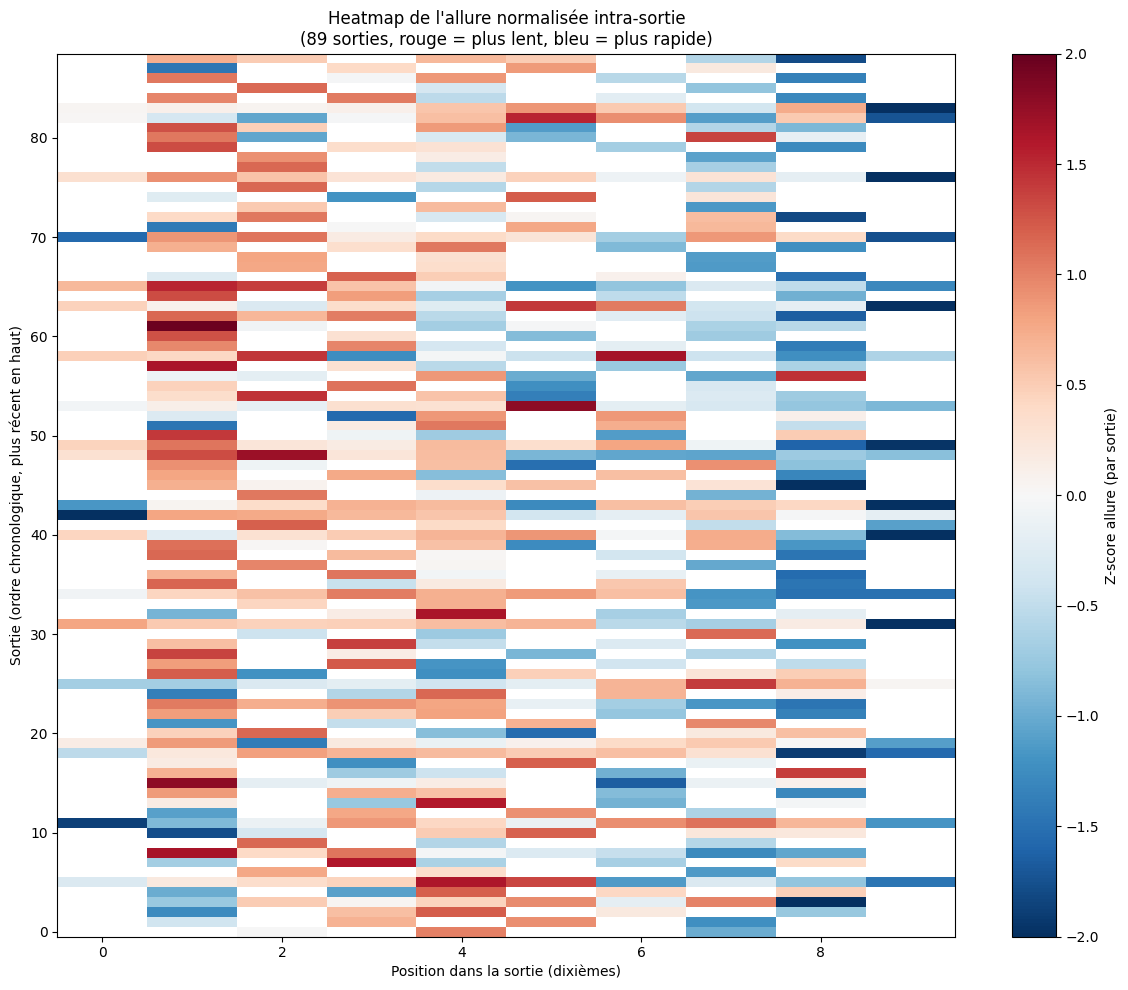

In [2]:
# Filtres : sorties avec au moins 3 km complets
mask = (~df_km["is_partial"]) & (df_km["pace_min_per_km"].between(3, 10))
sub = df_km[mask].copy()

# Filtrer sorties avec assez de km
counts = sub.groupby("activity_id")["km_index"].transform("count")
sub = sub[counts >= 3]

# Normaliser l'allure : centrée-réduite par sortie
sub["pace_z"] = sub.groupby("activity_id")["pace_min_per_km"].transform(
    lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0
)

# Bins de fraction complétée (10 tranches)
sub["frac_bin"] = pd.cut(sub["fraction_completed"], bins=np.linspace(0, 1, 11),
                          labels=False, include_lowest=True)

# Trier les sorties par date pour affichage chronologique
activity_order = sub.groupby("activity_id")["date"].first().sort_values().index.tolist()
sub["activity_rank"] = sub["activity_id"].map({aid: i for i, aid in enumerate(activity_order)})

# Pivot pour la heatmap
heatmap = sub.pivot_table(
    index="activity_rank", columns="frac_bin", values="pace_z", aggfunc="mean"
)

# Plot
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(heatmap.values, aspect="auto", cmap="RdBu_r",
               vmin=-2, vmax=2, interpolation="nearest")
ax.set_xlabel("Position dans la sortie (dixièmes)")
ax.set_ylabel("Sortie (ordre chronologique, plus récent en haut)")
ax.set_title(f"Heatmap de l'allure normalisée intra-sortie\n"
             f"({len(activity_order)} sorties, rouge = plus lent, bleu = plus rapide)")
ax.invert_yaxis()  # récent en haut
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Z-score allure (par sortie)")
plt.tight_layout()
plt.show()

# Heatmap V2 — Regroupée par bin de fraction complétée (résumé)

=== Allure normalisée par tranche de sortie (moyennes) ===
           mean    std  count
frac_bin                     
0        -0.326  0.989     24
1         0.359  0.888     83
2         0.360  0.801     58
3         0.324  0.649     71
4         0.249  0.700     92
5         0.138  1.129     50
6        -0.083  0.725     61
7        -0.179  0.763     68
8        -0.569  0.884     73
9        -1.473  0.754     25


C:\Users\nordi\AppData\Local\Temp\ipykernel_7336\1127400099.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_bin, patch_artist=True, showfliers=False,


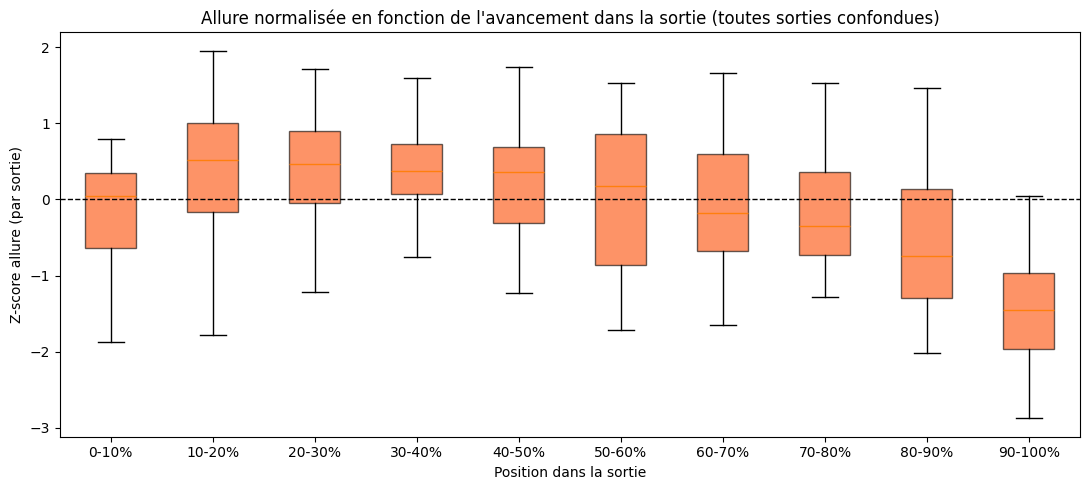

In [3]:
# Moyennes et écarts-types par bin
summary = sub.groupby("frac_bin")["pace_z"].agg(["mean", "std", "count"])
print("=== Allure normalisée par tranche de sortie (moyennes) ===")
print(summary.round(3))

# Vue synthétique en boxplot
fig, ax = plt.subplots(figsize=(11, 5))
data_by_bin = [sub[sub["frac_bin"] == b]["pace_z"].values
               for b in sorted(sub["frac_bin"].dropna().unique())]
bp = ax.boxplot(data_by_bin, patch_artist=True, showfliers=False,
                labels=[f"{int(b*10)}-{int((b+1)*10)}%" for b in sorted(sub["frac_bin"].dropna().unique())])
for patch in bp["boxes"]:
    patch.set_facecolor("#FC4C02")
    patch.set_alpha(0.6)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Position dans la sortie")
ax.set_ylabel("Z-score allure (par sortie)")
ax.set_title("Allure normalisée en fonction de l'avancement dans la sortie (toutes sorties confondues)")
plt.tight_layout()
plt.show()